# HS4002 Week 10

## Multiple Correspondence Analysis (MCA)

MCA is the categorical equivalent of PCA. It summarises the relationships among categorical variables into a low-dimensional space.

In Python, we use the `prince` library — a clean scikit-learn-style implementation. Equivalent to R's `ca::mjca()`.

In [2]:
%pip install prince

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 797.2/797.2 kB 20.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [prince]2m1/2 [prince]
Note: you may need to restart the kernel to use updated packages.


In [3]:
# !pip install pandas numpy plotnine prince statsmodels

import pandas as pd
import numpy as np
from plotnine import *
import warnings
warnings.filterwarnings('ignore')
import prince

In [4]:
raw_df = pd.read_csv("gss2022_mini2.csv")

chosen_variables = [
	'id', 'age', 'happy', 'yrlvmus', 'yrartxbt', 'yrmovie', 'yrcreat',
	'income16', 'prestg10', 'degree', 'race', 'sex', 'wrkstat', 'biokids', 'educ'
]
df = raw_df[chosen_variables].dropna().copy()

income_map = {
	1: 500,    2: 2000,   3: 3500,   4: 4500,   5: 5500,   6: 6500,
	7: 7500,   8: 9000,   9: 11250,  10: 13750, 11: 16250, 12: 18750,
	13: 21250, 14: 23750, 15: 27500, 16: 32500, 17: 37500, 18: 45000,
	19: 55000, 20: 67500, 21: 82500, 22: 100000, 23: 120000, 24: 140000,
	25: 160000, 26: 250000
}
df['income_cont']   = df['income16'].map(income_map)
df['income_1000']   = df['income_cont'] / 1000

df['binary_lvmus']  = (df['yrlvmus']  == 1).astype(int)
df['binary_artxbt'] = (df['yrartxbt'] == 1).astype(int)
df['binary_movie']  = (df['yrmovie']  == 1).astype(int)
df['binary_creat']  = (df['yrcreat']  == 1).astype(int)
df['omni'] = df[['binary_lvmus','binary_artxbt','binary_movie','binary_creat']].sum(axis=1)

df['race_bin']   = df['race'].astype(str)
df['race_cat']   = df['race'].map({1: 'White', 2: 'Black'}).fillna('Other')
df['ba_binary']  = (df['degree'] >= 3).astype(int)
df['sex_woman']  = np.where(df['sex'] == 2, 'Woman', 'Not Woman')
df['working']    = np.where(df['wrkstat'] <= 3, 'Working', 'Not Working')
df['happy_bin']  = (df['happy'] <= 2).astype(int)
df['happy_cat']  = np.where(df['happy'] <= 2, 'Happy', 'Not Happy')

# Walkthrough

## Step 1: Selecting Categorical Variables

Create `df_cats` with only binary/categorical variables: the four cultural participation measures plus gender.

Note: MCA requires string or categorical columns — convert integers to strings.

In [5]:
df_cats = df[[
	'binary_lvmus', 'binary_artxbt', 'binary_movie', 'binary_creat', 'sex_woman'
]].copy()

# Convert integer binary columns to strings so prince treats them as categories
for col in ['binary_lvmus', 'binary_artxbt', 'binary_movie', 'binary_creat']:
	df_cats[col] = df_cats[col].astype(str)

df_cats.head()

,binary_lvmus,binary_artxbt,binary_movie,binary_creat,sex_woman
4,0,0,0,0,Not Woman
17,1,1,1,0,Woman
18,1,0,1,0,Woman
20,0,0,0,0,Woman
22,0,0,0,0,Not Woman


## Step 2: Conduct MCA

Equivalent to `mjca(df_cats, lambda='adjusted')` in R.

In [6]:
mca = prince.MCA(n_components=2, n_iter=10)
mca = mca.fit(df_cats)

## Step 3: Examine the Model

Look at eigenvalues — how much variance each dimension explains.

In [7]:
print(mca.eigenvalues_summary)

          eigenvalue % of variance % of variance (cumulative)
component                                                    
0              0.346        34.59%                     34.59%
1              0.207        20.68%                     55.27%


## Step 4: Get Column (Category) Coordinates and Plot the Biplot

The biplot projects categories into the two-dimensional MCA space. Distances between categories reflect how often they co-occur.

In [6]:
# Get category coordinates
col_coords = mca.column_coordinates(df_cats)
print(col_coords.round(4))

                           0       1
binary_lvmus__0      -0.7821  0.3592
binary_lvmus__1       0.6847 -0.3145
binary_artxbt__0     -0.5118 -0.0958
binary_artxbt__1      0.9576  0.1793
binary_movie__0      -0.5382  0.5824
binary_movie__1       0.5440 -0.5888
binary_creat__0      -0.3678 -0.4812
binary_creat__1       0.7397  0.9676
sex_woman__Not Woman -0.3988 -0.3297
sex_woman__Woman      0.3491  0.2886


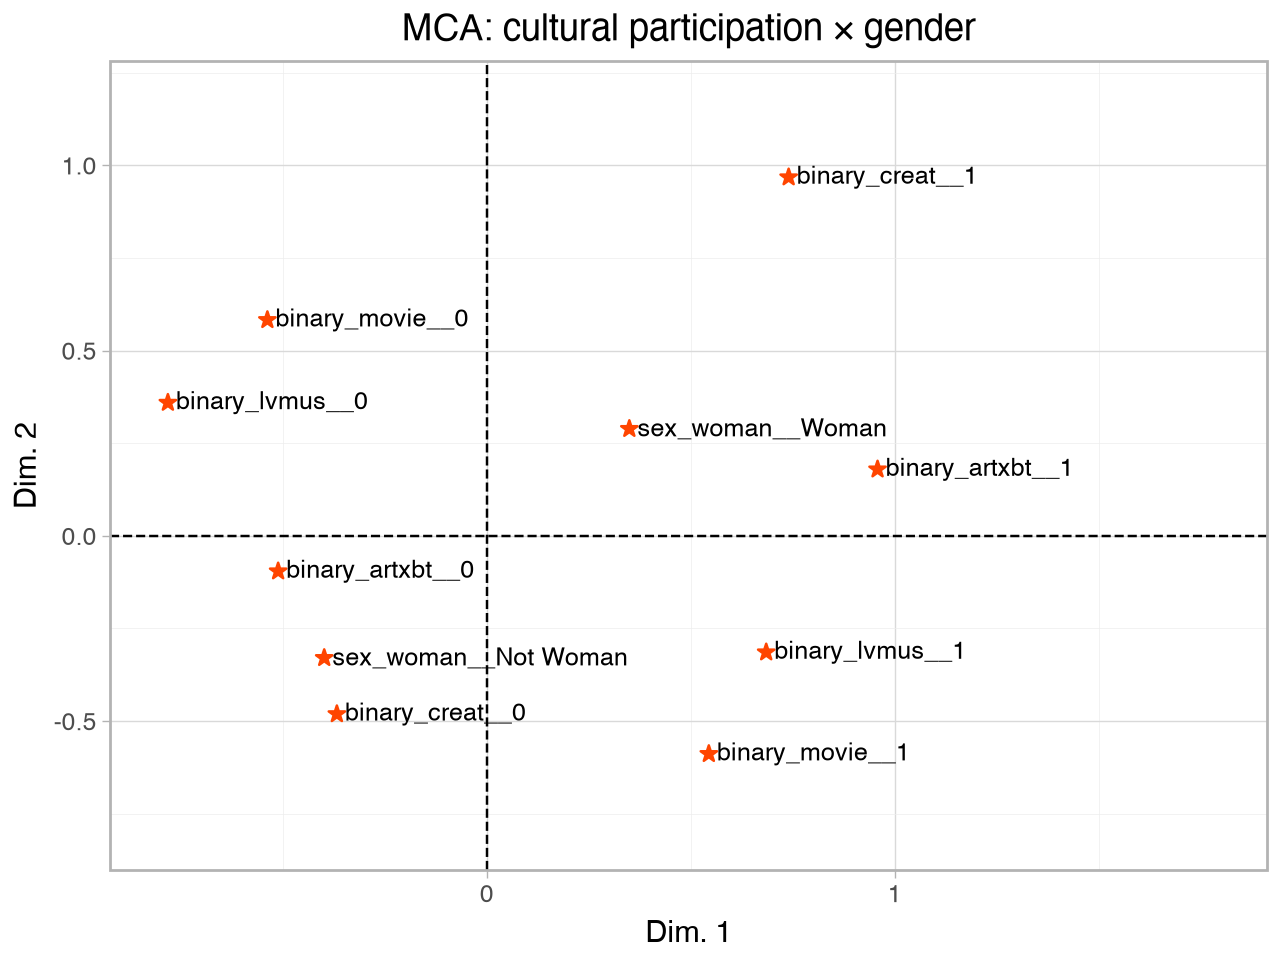

In [7]:
coords_plot = col_coords.reset_index()
coords_plot.columns = ['category', 'Dim1', 'Dim2']

(
	ggplot(coords_plot, aes(x='Dim1', y='Dim2', label='category')) +
	geom_point(size=3, color='orangered', shape='*') +
	geom_text(nudge_x=0.02, ha='left', size=9) +
	geom_vline(xintercept=0, linetype='dashed') +
	geom_hline(yintercept=0, linetype='dashed') +
	scale_x_continuous(expand=(0.08, 0, 0.02, 0.9)) +
	scale_y_continuous(expand=(0.15, 0.08)) +
	theme_light() +
	labs(y='Dim. 2', x='Dim. 1',
		 title='MCA: cultural participation × gender')
)

Try to make reasonable interpretations from this graph. What does Dimension 1 separate? What does Dimension 2 separate?

## Step 5: Using MCA dimensions in a regression


In [8]:
import statsmodels.formula.api as smf

row_coords = mca.row_coordinates(df_cats)
row_coords.columns = ['Dim1', 'Dim2']
reg_df = df[['biokids']].join(row_coords)

nb_mca = smf.negativebinomial('biokids ~ Dim1 + Dim2', data=reg_df).fit()
print(nb_mca.summary())
for name in ['Dim1', 'Dim2']:
	b = nb_mca.params[name]
	print(
		f'{name}: increase in the log count = {b:.3f}; '
		f'factor of change = {np.exp(b):.3f}; '
		f'percentage change = {100 * (np.exp(b) - 1):.1f}%'
	)

Optimization terminated successfully.
         Current function value: 1.697022
         Iterations: 11
         Function evaluations: 12
         Gradient evaluations: 12
                     NegativeBinomial Regression Results                      
Dep. Variable:                biokids   No. Observations:                  557
Model:               NegativeBinomial   Df Residuals:                      554
Method:                           MLE   Df Model:                            2
Date:                Wed, 21 Oct 2026   Pseudo R-squ.:                0.001424
Time:                        11:54:55   Log-Likelihood:                -945.24
converged:                       True   LL-Null:                       -946.59
Covariance Type:            nonrobust   LLR p-value:                    0.2597
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.4558      0.044     1

why use negative Binomial Regression: biokid is count variable, and Overdispersion

# Independent Analysis: Testing Bourdieusian Theories of Culture

Bourdieu argues that class shapes cultural taste. We'll test if inter-class differences in cultural consumption are visible in the MCA space.

Define class:
- Working-class: income < $50,000
- Middle-class: $50,000–$100,000
- Wealthy: > $100,000

In [9]:
df['income_cat'] = pd.cut(
	df['income_cont'],
	bins=[0, 50000, 100000, float('inf')],
	labels=['Working-class', 'Middle-class', 'Wealthy']
).astype(str)

df_cats2 = df[[
	'binary_lvmus', 'binary_artxbt', 'binary_movie', 'binary_creat',
	'sex_woman', 'income_cat'
]].copy()

for col in ['binary_lvmus', 'binary_artxbt', 'binary_movie', 'binary_creat']:
	df_cats2[col] = df_cats2[col].astype(str)

In [10]:
mca2 = prince.MCA(n_components=2, n_iter=10).fit(df_cats2)
print(mca2.eigenvalues_summary)

          eigenvalue % of variance % of variance (cumulative)
component                                                    
0              0.300        25.72%                     25.72%
1              0.203        17.36%                     43.09%


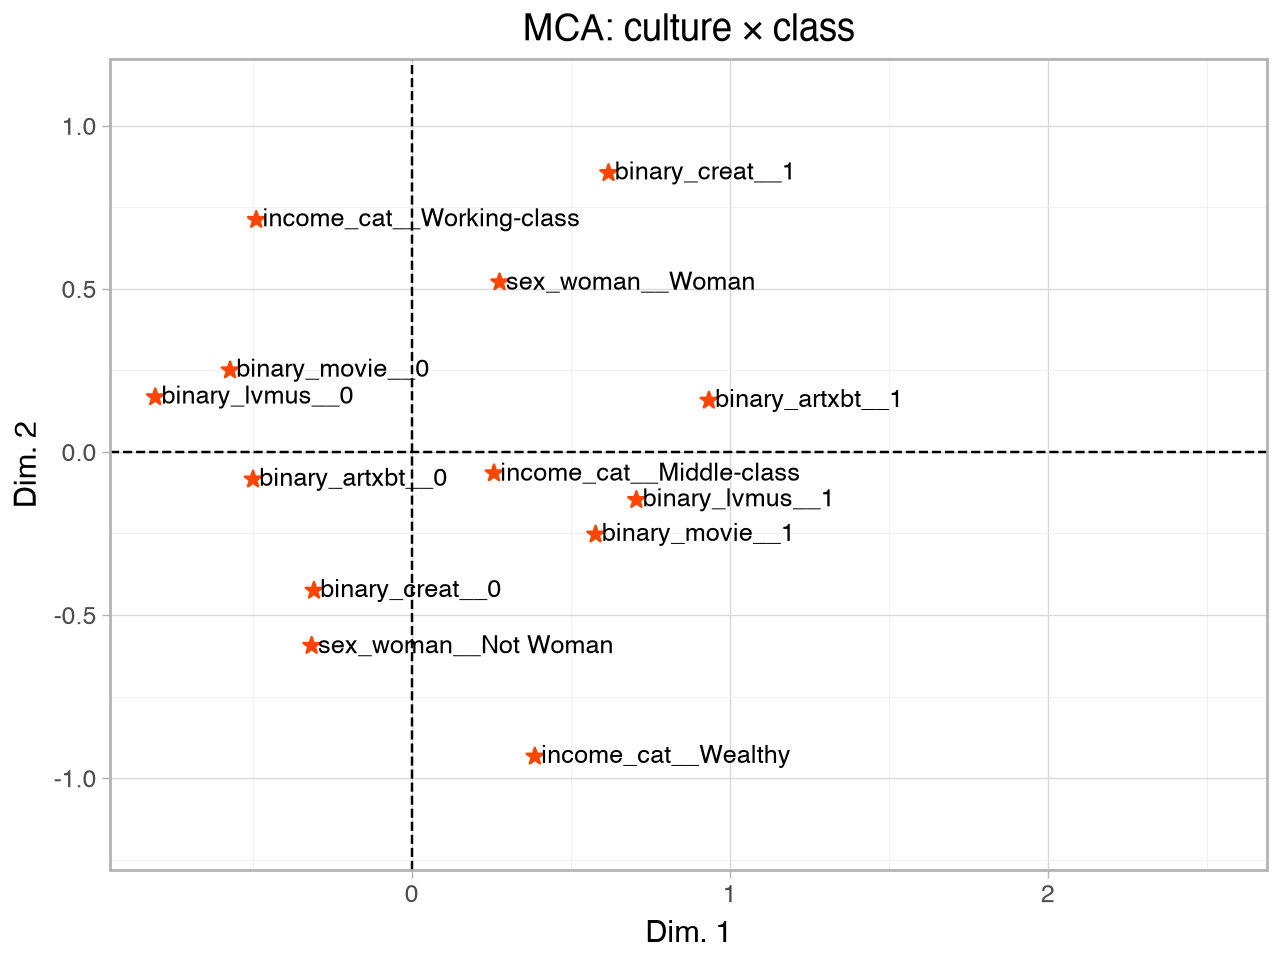

In [11]:
col_coords2 = mca2.column_coordinates(df_cats2).reset_index()
col_coords2.columns = ['category', 'Dim1', 'Dim2']

(
	ggplot(col_coords2, aes(x='Dim1', y='Dim2', label='category')) +
	geom_point(size=3, color='orangered', shape='*') +
	geom_text(nudge_x=0.02, ha='left', size=9) +
	geom_vline(xintercept=0, linetype='dashed') +
	geom_hline(yintercept=0, linetype='dashed') +
	scale_x_continuous(expand=(0.08, 0, 0.02, 1.7)) +
	scale_y_continuous(expand=(0.15, 0.08)) +
	theme_light() +
	labs(y='Dim. 2', x='Dim. 1', title='MCA: culture × class')
)

## How does class intersect with gender?

Create a combined class × gender variable, then include it in the MCA with the four cultural measures.

In [12]:
df['ixg'] = df['income_cat'] + ' + ' + df['sex_woman']

df_cats3 = df[[
	'binary_lvmus', 'binary_artxbt', 'binary_movie', 'binary_creat', 'ixg'
]].copy()
for col in ['binary_lvmus', 'binary_artxbt', 'binary_movie', 'binary_creat']:
	df_cats3[col] = df_cats3[col].astype(str)

mca3 = prince.MCA(n_components=2, n_iter=10).fit(df_cats3)
print(mca3.eigenvalues_summary)

          eigenvalue % of variance % of variance (cumulative)
component                                                    
0              0.364        20.23%                     20.23%
1              0.235        13.06%                     33.29%


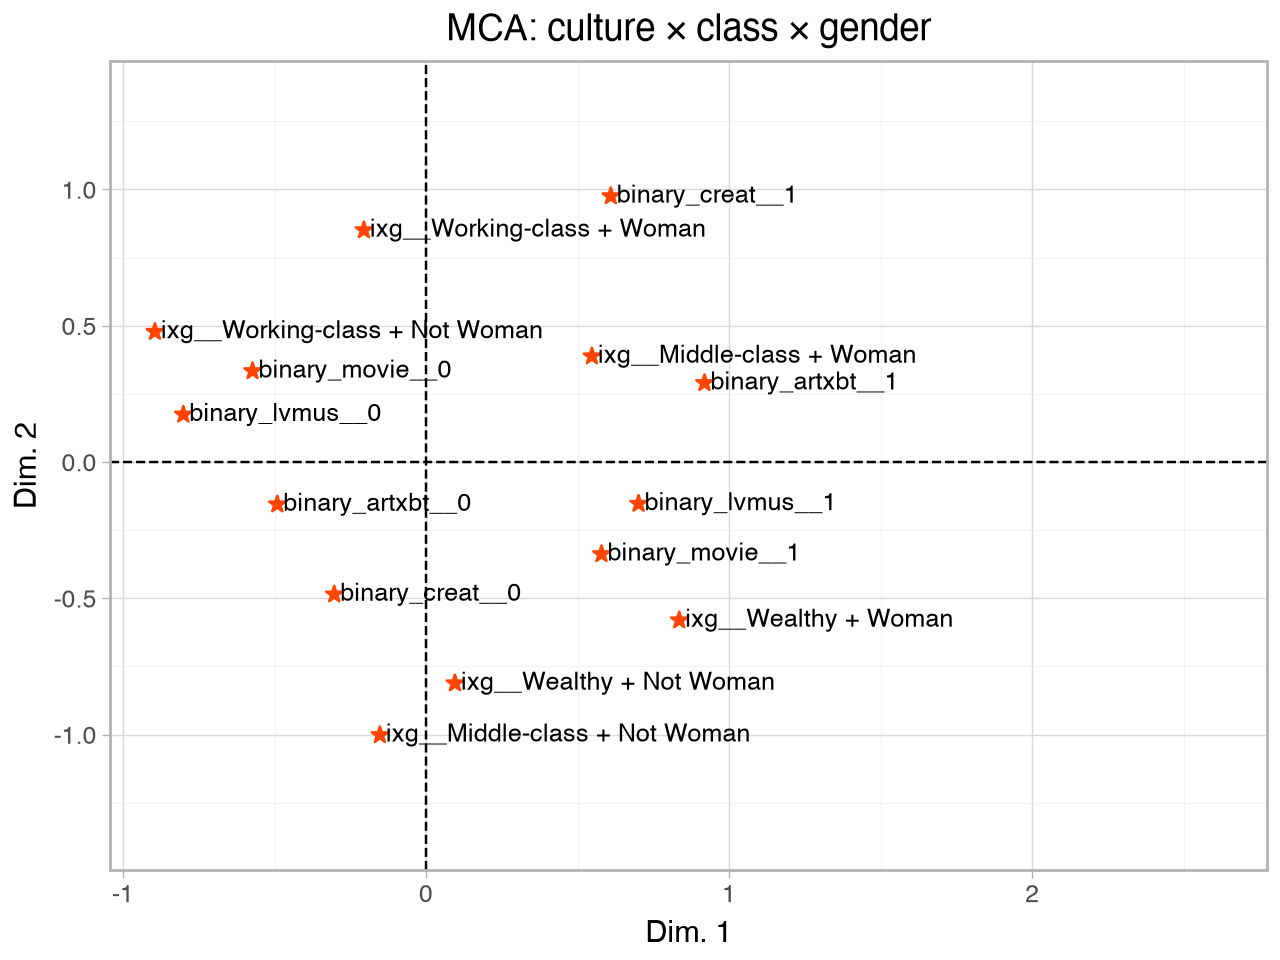

In [13]:
col_coords3 = mca3.column_coordinates(df_cats3).reset_index()
col_coords3.columns = ['category', 'Dim1', 'Dim2']

(
	ggplot(col_coords3, aes(x='Dim1', y='Dim2', label='category')) +
	geom_point(size=3, color='orangered', shape='*') +
	geom_text(nudge_x=0.02, ha='left', size=9) +
	geom_vline(xintercept=0, linetype='dashed') +
	geom_hline(yintercept=0, linetype='dashed') +
	scale_x_continuous(expand=(0.08, 0, 0.02, 1.8)) +
	scale_y_continuous(expand=(0.2, 0.1)) +
	theme_light() +
	labs(y='Dim. 2', x='Dim. 1', title='MCA: culture × class × gender')
)

What do you find? Does class intersect with gender in interesting ways?

Both working-class groups are on the negative side of Dimension 1, they have lower overall cultural participation.
middle-class women and non-women are located quite far, gender differences may lead to different cultural taste.
Wealthy women and non-women are both located at negative side of Dimension 2 and positive side of Dimension 1, which means that class difference may also influence the cultural participation and teste. 